# DS4 fridge profile

## Overview
Before we use the fridge in later phases, we need to know whether it carries a usable signal or is only good for marking events like the warm-up ([Phase 01, B1](../../docs/phases/01_eda.md#b1-ds4-fridge)). DS4 is a six-hourly Grafana export ([datasheet 4](../../docs/datasheets/04_fridge_environment.md)), so the question is whether anything resolvable happens at that resolution.

**Question.** Is fridge state a continuous covariate, or only an event marker?

**Method.** We split the record into cold epochs around the thermal cycle and data gaps, and line it up against the `periods.py` register and the two incidents (section 1). Then we check coverage and missing values (section 2), pick representative channels (section 3), and test whether MIX moves above its noise floor within an epoch (section 4). Last, we screen for level shifts and see whether the register explains them (section 5). Along the way B1 adds the thermal cycle to `periods.py` and writes DS4 rows to `noise_floor.parquet`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import periods
from qpu_drift.derived.noise import write_noise_rows
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.fridge import cold_epochs, cold_mask, load_fridge
from qpu_drift.sources.fridge.constants import MIX_CHANNEL as MIX, PT2_CHANNEL as PT2
from qpu_drift.sources.fridge.load import DEFAULT_PATH as FRIDGE_PATH

pd.set_option("display.max_rows", 200, "display.max_columns", 30, "display.width", 250)
w = load_fridge()
t = w.index.to_series()
cold = cold_mask(w)
warm = (w[MIX] > 1) | (w[PT2] > 10)
STAGES = {"MIX": MIX, "CLD": "temperature_DRI_CLD_S", "STL": "temperature_DRI_STL_S",
          "PT2": PT2, "PT1": "temperature_DRI_PT1_S"}
SHORT = {v: k for k, v in STAGES.items()}
print(f"{len(w)} rows x {w.shape[1]} channels, {t.min()} to {t.max()}; index dtype {w.index.dtype}")
print(f"cold rows {cold.sum()}, warm rows (MIX > 1 K or PT2 > 10 K) {warm.sum()}, neither {(~cold & ~warm).sum()}")


1503 rows x 49 channels, 2025-08-01 12:00:00+00:00 to 2026-09-03 12:00:00+00:00; index dtype datetime64[ms, UTC]
cold rows 1452, warm rows (MIX > 1 K or PT2 > 10 K) 49, neither 2


## 1. Provenance and strata

First we split the record into states. A row is *cold* when `cold_mask` passes it ([datasheet 4, section 6](../../docs/datasheets/04_fridge_environment.md#6-preprocessing-and-cleaning)), *warm* when MIX > 1 K or PT2 > 10 K, and *invalid* otherwise. A run of non-cold rows with at least one warm row is a *thermal cycle*. Nothing is recorded across a long gap, so a new *epoch* starts wherever two cold rows are more than 24 h apart (`cold_epochs`) - whether that's a thermal cycle or a DS4 gap.

In [2]:
blk = (cold != cold.shift()).cumsum()
b = (pd.DataFrame({"t": t, "warm": warm, "mix": w[MIX], "pt2": w[PT2]})[~cold]
     .groupby(blk[~cold])
     .agg(first=("t", "min"), last=("t", "max"), rows=("t", "size"), warm_rows=("warm", "sum"),
          max_MIX_K=("mix", "max"), max_PT2_K=("pt2", "max")))
b.insert(0, "last_cold_before", [t[cold & (t < f)].max() for f in b["first"]])
b["first_cold_after"] = [t[cold & (t > l)].min() for l in b["last"]]
b["kind"] = np.where(b["warm_rows"] > 0, "thermal cycle", "invalid rows")
b = b.reset_index(drop=True)
display(b)
display(w.loc[~cold & ~warm, list(STAGES.values())].rename(columns=SHORT))

,last_cold_before,first,last,rows,warm_rows,max_MIX_K,max_PT2_K,first_cold_after,kind
0,2026-03-09 00:00:00+00:00,2026-03-09 06:00:00+00:00,2026-03-21 18:00:00+00:00,49,49,44.9622,299.1952,2026-03-22 00:00:00+00:00,thermal cycle
1,2026-07-07 00:00:00+00:00,2026-07-07 06:00:00+00:00,2026-07-07 06:00:00+00:00,1,0,NaN,NaN,2026-07-08 18:00:00+00:00,invalid rows
2,2026-08-04 06:00:00+00:00,2026-08-04 12:00:00+00:00,2026-08-04 12:00:00+00:00,1,0,NaN,NaN,2026-08-04 18:00:00+00:00,invalid rows


,MIX,CLD,STL,PT2,PT1
timestamp,,,,,
2026-07-07 06:00:00+00:00,NaN,NaN,NaN,NaN,NaN
2026-08-04 12:00:00+00:00,NaN,NaN,NaN,NaN,NaN


**Results.**
- 1,503 rows × 49 channels, 2025-08-01 12:00 to 2026-09-03 12:00 UTC: 1,452 cold, 49 warm and 2 invalid.
- There's one thermal cycle, from the last cold reading at 2026-03-09 00:00 to the first cold one at 03-22 00:00, peaking at MIX 44.96 K and PT2 299.2 K.

Next, the stage temperatures through the cycle and over the 10 days before it.

In [3]:
def stages(frame: pd.DataFrame) -> pd.DataFrame:
    """Stage temperatures with MIX and CLD in mK, the rest in K."""
    out = frame[list(STAGES.values())].rename(columns=SHORT)
    out[["MIX", "CLD"]] *= 1e3
    return out.rename(columns={"MIX": "MIX_mK", "CLD": "CLD_mK"}).round(3)


cyc = b[b["kind"] == "thermal cycle"]
for _, c in cyc.iterrows():
    print(f"thermal cycle: last cold {c['last_cold_before']}, first cold after {c['first_cold_after']}")
    display(stages(w.loc[c["last_cold_before"]:c["first_cold_after"]]))
    pre = w.loc[c["last_cold_before"] - pd.Timedelta("10D"):c["last_cold_before"]]
    print("daily medians over the 10 days before")
    display(stages(pre.groupby(pre.index.floor("D")).median()))

thermal cycle: last cold 2026-03-09 00:00:00+00:00, first cold after 2026-03-22 00:00:00+00:00


,MIX_mK,CLD_mK,STL,PT2,PT1
timestamp,,,,,
2026-03-09 00:00:00+00:00,8.813,93.519,0.785,4.003,52.056
2026-03-09 06:00:00+00:00,10230.100,11030.100,11.462,4.146,51.446
2026-03-09 12:00:00+00:00,44962.200,57992.700,55.364,75.552,150.962
2026-03-09 18:00:00+00:00,44962.200,141872.000,134.855,142.475,227.609
2026-03-10 00:00:00+00:00,44962.200,149978.000,176.347,184.588,249.348
2026-03-10 06:00:00+00:00,44962.200,149978.000,189.105,233.821,276.257
2026-03-10 12:00:00+00:00,44962.200,149978.000,185.150,244.119,275.990
2026-03-10 18:00:00+00:00,44962.200,149978.000,182.739,256.859,280.158
2026-03-11 00:00:00+00:00,44962.200,149978.000,180.207,269.478,285.010


daily medians over the 10 days before


,MIX_mK,CLD_mK,STL,PT2,PT1
timestamp,,,,,
2026-02-27 00:00:00+00:00,8.975,93.553,0.784,3.984,51.558
2026-02-28 00:00:00+00:00,9.070,93.546,0.785,3.972,51.131
2026-03-01 00:00:00+00:00,8.993,93.397,0.784,3.970,51.194
2026-03-02 00:00:00+00:00,9.053,93.498,0.784,3.967,51.044
2026-03-03 00:00:00+00:00,8.916,93.507,0.784,3.971,51.222
2026-03-04 00:00:00+00:00,8.980,93.424,0.784,3.977,51.347
2026-03-05 00:00:00+00:00,9.212,93.798,0.784,3.980,51.471
2026-03-06 00:00:00+00:00,8.724,93.739,0.786,3.997,51.962
2026-03-07 00:00:00+00:00,8.648,93.549,0.786,3.997,51.955


**Results.**
- The stages creep up over the 3 days before the cycle (PT1 51.0 → 52.1 K).

The fridge takes a while to recover after a cycle, so we call an epoch *settled* from the first day whose daily MIX median stays at or below REF for 7 days (or to the epoch end), where REF is the p95 of all daily MIX medians.

In [4]:
tc = t[cold]
epoch = cold_epochs(w)[cold].astype(int)
ep = tc.groupby(epoch).agg(["min", "max", "size"]).set_axis(["first", "last", "rows"], axis=1)
ep["gap_before_h"] = (ep["first"] - ep["last"].shift()) / pd.Timedelta("1h")
ep["after_cycle"] = ep["first"].isin(cyc["first_cold_after"])

mix_mK = w.loc[cold, MIX] * 1e3
daily = mix_mK.groupby([epoch, mix_mK.index.floor("D")]).median()
REF = daily.quantile(0.95)
print(f"reference: p95 of the {len(daily)} daily MIX medians = {REF:.3f} mK")


def settle_day(d: pd.Series) -> pd.Timestamp:
    """First day from which the daily median stays at or below REF for 7 days (or to the epoch end)."""
    ok = (d <= REF).to_numpy()
    days = d.index.get_level_values(1)
    for i in range(len(ok)):
        if ok[i:i + 7].all() and (i + 7 <= len(ok) or days[-1] - days[i] < pd.Timedelta("7D")):
            return days[i]
    return pd.NaT


ep["settled_from"] = [settle_day(daily.loc[[k]]) for k in ep.index]
ep["settle_days"] = (ep["settled_from"] - ep["first"].dt.floor("D")) / pd.Timedelta("1D")
display(ep)
for k in ep.index:
    print(f"epoch {k}: first 14 daily MIX medians (mK):", daily.loc[k].head(14).round(2).tolist())
settled = pd.Series(False, index=w.index)
for k, e in ep.iterrows():
    settled |= (t >= e["settled_from"]) & (t <= e["last"]) & cold
ep_of = epoch.reindex(w.index).astype("Int64")
print(f"cold rows {cold.sum()}, settled cold rows {settled.sum()}")


reference: p95 of the 367 daily MIX medians = 9.861 mK


,first,last,rows,gap_before_h,after_cycle,settled_from,settle_days
epoch,,,,,,,
0,2025-08-01 12:00:00+00:00,2026-03-09 00:00:00+00:00,879,NaN,False,2025-08-03 00:00:00+00:00,2.0
1,2026-03-22 00:00:00+00:00,2026-06-11 18:00:00+00:00,328,312.0,True,2026-04-04 00:00:00+00:00,13.0
2,2026-07-02 18:00:00+00:00,2026-07-07 00:00:00+00:00,18,504.0,False,2026-07-03 00:00:00+00:00,1.0
3,2026-07-08 18:00:00+00:00,2026-09-03 12:00:00+00:00,227,42.0,False,2026-07-08 00:00:00+00:00,0.0


epoch 0: first 14 daily MIX medians (mK): [12.56, 9.88, 9.38, 9.36, 9.53, 9.61, 9.56, 9.59, 9.7, 9.33, 9.75, 9.87, 9.63, 9.84]
epoch 1: first 14 daily MIX medians (mK): [13.83, 12.87, 12.56, 11.89, 11.4, 11.09, 10.81, 10.32, 10.42, 10.24, 10.0, 9.93, 9.98, 9.76]
epoch 2: first 14 daily MIX medians (mK): [10.82, 9.56, 9.12, 8.9, 8.76, 8.81]
epoch 3: first 14 daily MIX medians (mK): [8.67, 8.78, 8.87, 8.79, 8.63, 8.57, 8.62, 8.63, 8.63, 8.46, 8.53, 8.61, 8.67, 8.7]
cold rows 1452, settled cold rows 1393


**Results.**
- There are four cold epochs, with REF = 9.861 mK. Epoch 0 has 879 rows and settles after 2 days; epoch 1 has 328 rows after the 312 h cycle and takes 13 days; epoch 2 has 18 rows after a 504 h gap and takes 1 day; epoch 3 has 227 rows after a 42 h gap and is settled at once.

Then we line DS4 up against the register: the 2026-03 outage, the two chip-wide `F01_FLAGS` windows and the `DS4_GAPS`. DS4 starts 2025-08-01, so the 2025 outages and the Q23 window are out of reach.

In [5]:
ds4_first, ds4_last = t.min().tz_localize(None), t.max().tz_localize(None)
ev = ([(p[0], "outage start") for p in periods.OUTAGES] + [(p[1], "outage end") for p in periods.OUTAGES]
      + [(f.period[0], f"F01 flag start: {f.what}") for f in periods.F01_FLAGS]
      + [(f.period[1], f"F01 flag end: {f.what}") for f in periods.F01_FLAGS]
      + [(p[0], "DS4 gap: last reading") for p in periods.DS4_GAPS]
      + [(p[1], "DS4 gap: first reading") for p in periods.DS4_GAPS]
      + [(u.at, f"untracked DS2 {u.kind}") for u in periods.UNTRACKED_DS2]
      + [(br.at, f"break: {br.what}") for br in periods.BREAKS if br.source != "ds4"])  # ds4 breaks come from this notebook
ev = pd.DataFrame(ev, columns=["at", "event"]).astype({"at": "datetime64[ns]"}).sort_values("at")
outside = (ev["at"] < ds4_first) | (ev["at"] > ds4_last)
print("register entries outside DS4, not checkable:", ev[outside].groupby(ev["event"].str.split(":").str[0]).size().to_dict())
ev = ev[~outside]
rd = pd.DataFrame({"reading": t.dt.tz_localize(None).astype("datetime64[ns]").to_numpy(),
                   "state": np.select([cold, warm], ["cold", "warm"], "invalid"),
                   "MIX_mK": (w[MIX] * 1e3).round(2).to_numpy(), "PT2_K": w[PT2].round(2).to_numpy()})
reg = pd.merge_asof(ev, rd.add_suffix("_before"), left_on="at", right_on="reading_before", direction="backward")
reg = pd.merge_asof(reg, rd.add_suffix("_after"), left_on="at", right_on="reading_after", direction="forward", allow_exact_matches=False)
reg["epoch"] = pd.merge_asof(ev, pd.DataFrame({"reading": rd["reading"], "epoch": ep_of.to_numpy()}), left_on="at",
                             right_on="reading", direction="backward")["epoch"].to_numpy()
display(reg)

register entries outside DS4, not checkable: {'F01 flag end': 1, 'F01 flag start': 1, 'break': 8, 'outage end': 2, 'outage start': 2, 'untracked DS2 unmatched': 6}


,at,event,reading_before,state_before,MIX_mK_before,PT2_K_before,reading_after,state_after,MIX_mK_after,PT2_K_after,epoch
0,2025-08-22 00:00:00,break: DS3 gating era 3,2025-08-22 00:00:00,cold,9.87,3.87,2025-08-22 06:00:00,cold,9.84,3.88,0.0
1,2025-09-03 19:05:16,untracked DS2 rollback,2025-09-03 18:00:00,cold,9.63,3.88,2025-09-04 00:00:00,cold,9.42,3.88,0.0
2,2026-02-26 19:05:15,untracked DS2 rollback,2026-02-26 18:00:00,cold,9.07,NaN,2026-02-27 00:00:00,cold,8.72,NaN,0.0
3,2026-03-09 19:42:45,F01 flag start: chip-wide shift over 5 MHz,2026-03-09 18:00:00,warm,44962.20,142.47,2026-03-10 00:00:00,warm,44962.20,184.59,NaN
4,2026-03-12 00:00:00,outage start,2026-03-12 00:00:00,warm,NaN,288.17,2026-03-12 06:00:00,warm,NaN,290.72,NaN
5,2026-03-17 00:00:00,DS4 gap: last reading,2026-03-17 00:00:00,warm,NaN,299.20,2026-03-17 18:00:00,warm,NaN,233.91,NaN
6,2026-03-17 18:00:00,DS4 gap: first reading,2026-03-17 18:00:00,warm,NaN,233.91,2026-03-18 00:00:00,warm,NaN,233.91,NaN
7,2026-03-24 00:00:00,break: couplings 1-10 and 1-2 reverse,2026-03-24 00:00:00,cold,12.63,3.82,2026-03-24 06:00:00,cold,12.63,3.83,1.0
8,2026-03-24 00:00:00,outage end,2026-03-24 00:00:00,cold,12.63,3.82,2026-03-24 06:00:00,cold,12.63,3.83,1.0
9,2026-03-24 12:03:12,untracked DS2 rollback,2026-03-24 12:00:00,cold,12.50,3.83,2026-03-24 18:00:00,cold,12.33,3.82,1.0


**Results.**
- The register lines up. The chip-wide f01 flag of 2026-03-09 19:42 falls inside the warm-up (MIX 44,962 mK), and both its end (03-24) and the outage end are cold but before epoch 1 settles (MIX 12.63 mK). The July DS4 gap runs 2026-06-11 18:00 to 07-02 18:00. PT2 has no reading at the 2026-02-26 rollback - it falls in the 02-20 to 02-27 run of cleared zeros (section 2). 18 register entries fall outside the DS4 window.

Last, the two `INCIDENTS`, which each run from the first run with off results to the first good run after a DS2 rollback. For every run from 2 days before each window to its end, we list result ids, warnings, the DS4 reading up to 6 h before, and the f01 shift against the 10 `calibrate_1q` runs before that 2-day lead-in. The same cell checks `THERMAL_CYCLES`, its `ds4` break and `SETTLING` in `periods.py` against what we compute here, as A4 section 6 does.

In [6]:
from qpu_drift.derived.run_map import load_run_entities, load_run_map

# Incidents: every run from 2 days before each window to its end, with the DS4 reading up to 6 h before it
runs, ent = load_run_map(), load_run_entities()
f01 = ent[(ent["routine"] == "calibrate_1q") & (ent["param"] == "freq")]
print("last cold DS4 reading before each thermal cycle:", [str(c) for c in cyc["last_cold_before"].dt.tz_localize(None)])
for inc in periods.INCIDENTS:
    a, b = inc.period
    lead = a - pd.Timedelta("2D")  # baseline runs end before the 2-day lead-in, so the lead-in isn't compared with itself
    base_runs = np.sort(f01.loc[f01["start"] < lead, "start"].unique())[-10:]
    base = f01[f01["start"].isin(base_runs)].groupby("qubit")["new"].median()
    fw = f01[(f01["start"] >= lead) & (f01["start"] <= b)]
    fs = (fw.assign(m=fw["measured"].fillna(False).astype(bool), shift_MHz=(fw["new"] - fw["qubit"].map(base)) / 1e6)
          .groupby("start").agg(f01_measured=("m", "sum"), f01_shift_med_MHz=("shift_MHz", "median"),
                                f01_shift_min_MHz=("shift_MHz", "min")))
    r = runs[(runs["start"] >= lead) & (runs["start"] <= b)][["start", "routine", "n_result_ids", "n_warnings"]]
    r = r.merge(fs, left_on="start", right_index=True, how="left").astype({"start": "datetime64[ns]"}).sort_values("start")
    r = pd.merge_asof(r, rd.rename(columns={"reading": "ds4_reading"}), left_on="start", right_on="ds4_reading",
                      direction="backward", tolerance=pd.Timedelta("6h"))
    r["in_incident"] = periods.within(r["start"], inc.period)
    r["in_chip_f01_flag"] = periods.f01_flagged(r["start"], np.full(len(r), -1))  # chip-wide flags only
    rb = [(str(u.at), str(u.restores)) for u in periods.UNTRACKED_DS2 if u.kind == "rollback" and lead < u.at <= b]
    print(f"\n{inc.what}: {a} to {b}; rollbacks (at, restores): {rb}")
    print(f"f01 shift = new minus the per-qubit median new over the {len(base_runs)} calibrate_1q runs "
          f"{pd.Timestamp(base_runs[0])} to {pd.Timestamp(base_runs[-1])}")
    display(r.round({"f01_shift_med_MHz": 2, "f01_shift_min_MHz": 2}))

computed = [(e["first"].tz_localize(None), e["settled_from"].tz_localize(None)) for _, e in ep[ep["after_cycle"]].iterrows()]
print("SETTLING register:", [tuple(map(str, p)) for p in periods.SETTLING], "| computed:", [tuple(map(str, p)) for p in computed],
      "| match:", list(periods.SETTLING) == computed)
cyc_ends = [c.tz_localize(None) for c in cyc["first_cold_after"]]
print("thermal-cycle breaks:", [(str(br.at), br.what) for br in periods.BREAKS if br.source == "ds4"],
      "| computed cycle ends:", [str(c) for c in cyc_ends],
      "| match:", [br.at for br in periods.BREAKS if br.source == "ds4"] == cyc_ends)
cyc_spans = [(c["last_cold_before"].tz_localize(None), c["first_cold_after"].tz_localize(None)) for _, c in cyc.iterrows()]
print("THERMAL_CYCLES register:", [tuple(map(str, p)) for p in periods.THERMAL_CYCLES],
      "| match:", list(periods.THERMAL_CYCLES) == cyc_spans)


last cold DS4 reading before each thermal cycle: ['2026-03-09 00:00:00']



thermal cycle: 2026-03-09 08:45:16 to 2026-03-24 14:45:52; rollbacks (at, restores): [('2026-03-24 12:03:12', '2026-03-05 20:11:50')]
f01 shift = new minus the per-qubit median new over the 10 calibrate_1q runs 2026-03-02 08:45:16 to 2026-03-06 19:42:38


,start,routine,n_result_ids,n_warnings,f01_measured,f01_shift_med_MHz,f01_shift_min_MHz,ds4_reading,state,MIX_mK,PT2_K,in_incident,in_chip_f01_flag
0,2026-03-07 08:45:17,calibrate_1q,421,7,30.0,0.00,-0.04,2026-03-07 06:00:00,cold,8.68,4.00,False,False
1,2026-03-07 09:03:59,calibrate_2q,31,2,NaN,NaN,NaN,2026-03-07 06:00:00,cold,8.68,4.00,False,False
2,2026-03-07 19:05:21,mixer_calibration,192,<NA>,NaN,NaN,NaN,2026-03-07 18:00:00,cold,8.64,3.99,False,False
3,2026-03-07 19:42:37,calibrate_1q,420,7,30.0,-0.00,-0.06,2026-03-07 18:00:00,cold,8.64,3.99,False,False
4,2026-03-07 20:01:06,calibrate_2q,31,2,NaN,NaN,NaN,2026-03-07 18:00:00,cold,8.64,3.99,False,False
5,2026-03-07 20:11:59,benchmarking,70,6,NaN,NaN,NaN,2026-03-07 18:00:00,cold,8.64,3.99,False,False
6,2026-03-08 08:45:16,calibrate_1q,424,6,30.0,-0.00,-0.05,2026-03-08 06:00:00,cold,8.69,4.00,False,False
7,2026-03-08 09:04:03,calibrate_2q,31,2,NaN,NaN,NaN,2026-03-08 06:00:00,cold,8.69,4.00,False,False
8,2026-03-08 19:05:22,mixer_calibration,192,<NA>,NaN,NaN,NaN,2026-03-08 18:00:00,cold,8.71,4.00,False,False
9,2026-03-08 19:42:41,calibrate_1q,413,16,30.0,0.00,-0.03,2026-03-08 18:00:00,cold,8.71,4.00,False,False



chip-wide f01 shift, fridge state unknown (DS4 gap): 2026-07-02 08:45:41 to 2026-07-05 21:54:09; rollbacks (at, restores): [('2026-07-05 21:25:30', '2026-07-01 20:04:47')]
f01 shift = new minus the per-qubit median new over the 10 calibrate_1q runs 2026-06-25 08:45:42 to 2026-06-29 19:38:47


,start,routine,n_result_ids,n_warnings,f01_measured,f01_shift_med_MHz,f01_shift_min_MHz,ds4_reading,state,MIX_mK,PT2_K,in_incident,in_chip_f01_flag
0,2026-06-30 08:45:41,calibrate_1q,417,10,30.0,-0.00,-0.07,NaT,NaN,NaN,NaN,False,False
1,2026-06-30 09:03:37,calibrate_2q,27,1,NaN,NaN,NaN,NaT,NaN,NaN,NaN,False,False
2,2026-06-30 19:06:04,mixer_calibration,192,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,NaN,False,False
3,2026-06-30 19:40:02,calibrate_1q,412,15,30.0,-0.00,-0.10,NaT,NaN,NaN,NaN,False,False
4,2026-06-30 19:58:06,calibrate_2q,27,0,NaN,NaN,NaN,NaT,NaN,NaN,NaN,False,False
5,2026-06-30 20:06:36,benchmarking,65,11,NaN,NaN,NaN,NaT,NaN,NaN,NaN,False,False
6,2026-07-01 08:45:40,calibrate_1q,425,6,30.0,-0.00,-0.02,NaT,NaN,NaN,NaN,False,False
7,2026-07-01 09:03:42,calibrate_2q,27,1,NaN,NaN,NaN,NaT,NaN,NaN,NaN,False,False
8,2026-07-01 19:05:40,mixer_calibration,192,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,NaN,False,False
9,2026-07-01 19:38:11,calibrate_1q,415,14,30.0,-0.00,-0.06,NaT,NaN,NaN,NaN,False,False


SETTLING register: [('2026-03-22 00:00:00', '2026-04-04 00:00:00')] | computed: [('2026-03-22 00:00:00', '2026-04-04 00:00:00')] | match: True
thermal-cycle breaks: [('2026-03-22 00:00:00', 'thermal cycle ends (f01 level shift)')] | computed cycle ends: ['2026-03-22 00:00:00'] | match: True
THERMAL_CYCLES register: [('2026-03-09 00:00:00', '2026-03-22 00:00:00')] | match: True


**Results.**
- `THERMAL_CYCLES`, `SETTLING` (2026-03-22 to 04-04) and the `ds4` break (03-22 00:00) all match what we compute.
- In the 2 days before each incident, `calibrate_1q` runs have 412–425 ids, 6–16 warnings and a median f01 shift of 0.00 MHz (min −0.02 to −0.10 MHz), against baselines from 2026-03-02 to 03-06 and 06-25 to 06-29. The last July lead-in run, benchmarking at 07-01 20:05:04 (65 ids, 10 warnings), is outside the incident.
- **Thermal-cycle incident.** It starts 2026-03-09 08:45:16 with 224 ids, 77 warnings and a median shift of −8.61 MHz, with DS4 already warm. The rollback at 03-24 12:03:12 restores 03-05 20:11:50, and the first good run at 03-24 14:45:52 has 411 ids, 11 warnings and a median shift of −0.94 MHz (min −8.74 MHz), at MIX 12.50 mK.
- **July incident.** It starts 2026-07-02 08:45:41 with 216 ids, 82 warnings and a median shift of −15.22 MHz, with no DS4 reading within 6 h. From 07-02 18:00 DS4 is cold and MIX falls 10.82 → 8.77 mK, while the median shift goes −20.39 → −23.16 MHz and the min −60.13 → −126.44 MHz. The rollback at 07-05 21:25:30 restores 07-01 20:04:47, and the first good run at 07-05 21:54:09 has 405 ids, 17 warnings and a median shift of −0.00 MHz (min −0.11 MHz).

## 2. Coverage and missingness

Next, how much of each channel we actually have. We take each channel's first and last valid reading and its density, over the whole record and over its own window - channels that stop early only get correlated within their own window (section 3).

In [7]:
nn = w.notna()
cov = pd.DataFrame({"first_valid": w.apply(lambda s: s.first_valid_index()),
                    "last_valid": w.apply(lambda s: s.last_valid_index()),
                    "density": nn.mean().round(4)})
cov["window_density"] = [round(nn.loc[a:z, c].mean(), 4) for c, a, z in zip(cov.index, cov["first_valid"], cov["last_valid"])]
cov["early_only"] = cov["last_valid"] < t.max()
display(cov.sort_values(["early_only", "density"]))
early = cov.index[cov["early_only"]].tolist()
full = cov.index[~cov["early_only"]].tolist()
print(f"{len(early)} early-only channels; last_valid:", cov.loc[early, "last_valid"].unique().tolist())
print(f"{len(full)} full-coverage channels; lowest density {cov.loc[full, 'density'].min()}")

,first_valid,last_valid,density,window_density,early_only
temperature_DRI_PT1_S,2025-08-01 12:00:00+00:00,2026-09-03 12:00:00+00:00,0.9348,0.9348,False
temperature_DRI_PT2_S,2025-08-01 12:00:00+00:00,2026-09-03 12:00:00+00:00,0.9348,0.9348,False
temperature_DRI_STL_S,2025-08-01 12:00:00+00:00,2026-09-03 12:00:00+00:00,0.9348,0.9348,False
temperature_PTR1_PT1_S,2025-08-01 12:00:00+00:00,2026-09-03 12:00:00+00:00,0.9348,0.9348,False
temperature_PTR1_PT2_S,2025-08-01 12:00:00+00:00,2026-09-03 12:00:00+00:00,0.9348,0.9348,False
temperature_SRB_GGS_CL_SRB_GGS_S,2025-08-01 12:00:00+00:00,2026-09-03 12:00:00+00:00,0.9348,0.9348,False
temperature_DRI_MIX_CL_DRI_MIX_S,2025-08-01 12:00:00+00:00,2026-09-03 12:00:00+00:00,0.9780,0.9780,False
temperature_DRI_CLD_S,2025-08-01 12:00:00+00:00,2026-09-03 12:00:00+00:00,0.9800,0.9800,False
inlet_water_temperature_3CL_PTR_3CL_PTR_01,2025-08-01 12:00:00+00:00,2026-09-03 12:00:00+00:00,0.9980,0.9980,False
oil_temperature_3CL_PTR_3CL_PTR_01,2025-08-01 12:00:00+00:00,2026-09-03 12:00:00+00:00,0.9980,0.9980,False


8 early-only channels; last_valid: [Timestamp('2025-12-02 06:00:00+0000', tz='UTC')]
41 full-coverage channels; lowest density 0.9348


**Results.**
- 41 channels cover the whole record (density 0.9993), and 8 stop at 2025-12-02 06:00: the PSU/UPS voltages, two electronics temperatures, three motor currents and `pressure_3SP_PG_01`.

We also count rows per month and in the all-four study period (`STUDY_PERIODS`).

In [8]:
month = t.dt.tz_localize(None).dt.to_period("M")
display(pd.DataFrame({"rows": t.groupby(month).size(), "cold": cold.groupby(month).sum(), "settled": settled.groupby(month).sum(),
                      "MIX_valid": nn[MIX].groupby(month).sum(), "early_all_valid": nn[early].all(axis=1).groupby(month).sum()}).T)
a0, a1 = periods.STUDY_PERIODS["all"]
ina = periods.within(t, (a0, a1))
print(f"study period 'all' {a0.date()} to {a1.date()}: rows {ina.sum()}, cold {(cold & ina).sum()}, settled {(settled & ina).sum()}")

timestamp,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
rows,122,120,124,120,124,124,112,122,120,124,44,112,124,11
cold,122,120,124,120,124,124,112,73,120,124,44,111,123,11
settled,116,120,124,120,124,124,112,33,108,124,44,110,123,11
MIX_valid,122,120,124,120,124,124,112,91,120,124,44,111,123,11
early_all_valid,122,120,124,120,6,0,0,0,0,0,0,0,0,0


study period 'all' 2025-08-01 to 2026-08-19: rows 1440, cold 1389, settled 1330


**Results.**
- June 2026 has only 44 rows (the DS4 gap). The four-dataset study period holds 1,440 rows, of which 1,389 are cold and 1,330 settled.

The build already sets exact zeros in temperature channels to NaN (`zeros_to_nan` in the catalog, [datasheet 4, section 6](../../docs/datasheets/04_fridge_environment.md#6-preprocessing-and-cleaning)), so we check none are left in cold rows and see where the gaps they leave fall. From here on, the analysis frame `x` holds settled cold rows only.

In [9]:
cat = pd.read_parquet(FRIDGE_PATH.parent / "channel_catalog.parquet").set_index("metric")
cleared = cat.loc[cat["kept"] & (cat["zeros_to_nan"] > 0), "zeros_to_nan"]
print("exact zeros the build set to NaN, per kept channel:", cleared.to_dict())
z = w[cold] == 0
print("exact zeros left in cold rows:", z.sum()[z.sum() > 0].to_dict())
miss = w.loc[cold, cleared.index].isna()
mc = miss.sum()[miss.sum() > 0]
print("missing cold rows in those channels:", mc.to_dict())
zr = []
for c in mc.index:
    s = miss[c]
    g = s.ne(s.shift()).cumsum()
    zr += [(c, r.index.min(), r.index.max(), len(r)) for _, r in s[s].groupby(g[s])]
zr = pd.DataFrame(zr, columns=["channel", "first", "last", "rows"])
display(zr.groupby(["first", "last", "rows"])["channel"].agg(", ".join).reset_index())
miss_rows = miss[mc.index].any(axis=1)
print("MIX and CLD on those rows (mK):")
display(stages(w.loc[miss_rows[miss_rows].index])[["MIX_mK", "CLD_mK"]].describe().loc[["count", "min", "max"]])
x = w.where(settled)
print(f"analysis frame x: {x.notna().any(axis=1).sum()} settled cold rows")


exact zeros the build set to NaN, per kept channel: {'bearing_temperature_3CL_TP_3CL_TP_01': 1, 'bearing_temperature_3CL_TP_3CL_TP_02': 1, 'electronics_temperature_3CL_TP_3CL_TP_01': 1, 'electronics_temperature_3CL_TP_3CL_TP_02': 1, 'inlet_water_temperature_3CL_PTR_3CL_PTR_01': 2, 'inlet_water_temperature_3CL_PTR_3CL_PTR_02': 1, 'motor_casing_temperature_3CL_TP_3CL_TP_01': 1, 'motor_casing_temperature_3CL_TP_3CL_TP_02': 1, 'oil_temperature_3CL_PTR_3CL_PTR_01': 2, 'oil_temperature_3CL_PTR_3CL_PTR_02': 1, 'outlet_water_temperature_3CL_PTR_3CL_PTR_01': 2, 'outlet_water_temperature_3CL_PTR_3CL_PTR_02': 1, 'power_stage_temperature_3CL_TP_3CL_TP_01': 1, 'power_stage_temperature_3CL_TP_3CL_TP_02': 1, 'pump_casing_temperature_3CL_TP_3CL_TP_01': 1, 'pump_casing_temperature_3CL_TP_3CL_TP_02': 1, 'temperature_DRI_CLD_S': 29, 'temperature_DRI_MIX_CL_DRI_MIX_S': 32, 'temperature_DRI_PT1_S': 97, 'temperature_DRI_PT2_S': 97, 'temperature_DRI_STL_S': 97, 'temperature_PTR1_PT1_S': 97, 'temperature_PTR1

,first,last,rows,channel
0,2025-10-17 18:00:00+00:00,2025-10-20 00:00:00+00:00,10,"temperature_DRI_PT1_S, temperature_DRI_PT2_S, ..."
1,2026-02-20 12:00:00+00:00,2026-02-27 00:00:00+00:00,27,"temperature_DRI_PT1_S, temperature_DRI_PT2_S, ..."
2,2026-08-04 18:00:00+00:00,2026-08-19 06:00:00+00:00,59,"temperature_DRI_PT1_S, temperature_DRI_PT2_S, ..."


MIX and CLD on those rows (mK):


,MIX_mK,CLD_mK
count,96.000,96.000
min,8.317,92.782
max,9.923,94.037


analysis frame x: 1393 settled cold rows


**Results.**
- The build cleared exact zeros in 24 kept temperature channels: 97 each in the six stage channels below, 32 in MIX, 29 in CLD and 1–2 in each of 16 compressor-plant temperatures. None are left in cold rows.
- The six stage channels `temperature_DRI_PT1_S`, `_DRI_PT2_S`, `_DRI_STL_S`, `_PTR1_PT1_S`, `_PTR1_PT2_S` and `_SRB_GGS` are missing in the same 96 cold rows, in three runs (10, 27 and 59 rows) from 2025-10-17 18:00, 2026-02-20 12:00 and 2026-08-04 18:00. MIX stays at 8.32–9.92 mK on those rows, so the cold mask keeps them.
- `x` holds 1,393 settled cold rows.

## 3. Marginals

With 49 channels, we want a handful of representatives. For each channel we look at its settled cold distribution (robust sd = 1.4826 × MAD), its unit, and its quantum - the smallest step between distinct values. Temperatures are in K except the water temperatures, which are in °C ([datasheet 4, section 4](../../docs/datasheets/04_fridge_environment.md#4-composition-and-structure)); other units are unconfirmed. `int_degC_share` is the share of temperature values that land on a whole °C.

In [10]:
def quantum(s: pd.Series) -> float:
    """Smallest gap between distinct values."""
    u = np.unique(s.dropna().to_numpy())
    return float(np.diff(u).min()) if len(u) > 1 else np.nan


def rsd(s: pd.Series) -> float:
    """Robust sd: 1.4826 times the median absolute deviation."""
    return 1.4826 * (s - s.median()).abs().median()


marg = pd.DataFrame({"n": x.count(), "median": x.median(), "robust_sd": x.apply(rsd), "sd": x.std(),
                     "p05": x.quantile(0.05), "p95": x.quantile(0.95), "n_unique": x.nunique(), "quantum": x.apply(quantum)})
marg["quantum_over_rsd"] = marg["quantum"] / marg["robust_sd"]
marg["int_degC_share"] = x.apply(lambda s: np.isclose((s.dropna() - 273.15) % 1, 0, atol=1e-6).mean()
                                 if "temperature" in s.name else np.nan)
marg["unit"] = np.select([marg.index.str.contains("water_temperature"), marg.index.str.contains("temperature")],
                         ["degC", "K"], "unconfirmed")  # water temperatures are degC (datasheet 4, section 4)
with pd.option_context("display.float_format", "{:.4g}".format):
    display(marg.sort_values("quantum_over_rsd"))


,n,median,robust_sd,sd,p05,p95,n_unique,quantum,quantum_over_rsd,int_degC_share,unit
low_side_pressure_3CL_PTR_3CL_PTR_02,1393,7.671e+05,6237,6266,7.623e+05,7.803e+05,1390,0.0526,8.434e-06,NaN,unconfirmed
flow_3CL_FM_01,1393,0.0004601,1.07e-05,1.011e-05,0.0004424,0.0004755,1370,9.313e-11,8.7e-06,NaN,unconfirmed
low_side_pressure_3CL_PTR_3CL_PTR_01,1393,7.7e+05,5455,1.302e+04,7.653e+05,8.035e+05,1387,0.0526,9.642e-06,NaN,unconfirmed
high_side_pressure_3CL_PTR_3CL_PTR_02,1393,2.153e+06,8284,9346,2.146e+06,2.174e+06,1380,0.2104,2.54e-05,NaN,unconfirmed
high_side_pressure_3CL_PTR_3CL_PTR_01,1393,2.181e+06,8156,1.817e+04,2.141e+06,2.189e+06,1383,0.2104,2.58e-05,NaN,unconfirmed
temperature_DRI_PT1_S,1297,48.75,1.863,1.886,44.64,51.01,1264,0.0001,5.368e-05,0,K
temperature_PTR1_PT1_S,1297,42.65,1.201,1.386,41.11,45.87,1266,0.0001,8.325e-05,0,K
temperature_DRI_MIX_CL_DRI_MIX_S,1393,0.00908,0.000365,0.0003908,0.008628,0.00978,1310,1e-07,0.000274,0,K
temperature_DRI_CLD_S,1393,0.09323,0.0002992,0.0003964,0.09239,0.09366,1274,1e-07,0.0003342,0,K
motor_current_3CL_CP_01,486,3.512,0.01379,0.01523,3.488,3.536,477,7.391e-06,0.0005361,NaN,unconfirmed


**Results.**
- MIX has a median of 9.08 mK, a robust sd of 0.365 mK and a quantum of 1e-7 K (quantum / robust sd 2.7e-4). Every stage resolves its spread far above its quantum.

To group the channels we use average linkage on the distance $1 - |\rho_\text{S}|$ (Spearman; pairs with under 100 shared rows count as distance 1), stopping once the closest two clusters are more than 0.5 apart. The five stages are always representatives. Each cluster of 3 or more adds the member with the highest mean $|\rho_\text{S}|$ to the rest of the cluster, as long as it's *eligible*: full coverage and quantum / robust sd < 0.1.

In [11]:
rho = x.corr(method="spearman", min_periods=100)
print("pairs with fewer than 100 shared rows:", int(rho.isna().to_numpy().sum() // 2))
CUT = 0.5


def average_linkage(rho: pd.DataFrame, cut: float) -> list[list[str]]:
    """Merge the closest clusters (mean 1 - |rho|) until the closest pair is further apart than cut."""
    d = (1 - rho.abs()).fillna(1)
    cl = [[c] for c in rho.columns]
    while len(cl) > 1:
        best = min((d.loc[a, b].to_numpy().mean(), i, j) for i, a in enumerate(cl) for j, b in enumerate(cl) if i < j)
        if best[0] > cut:
            break
        _, i, j = best
        cl[i] += cl.pop(j)
    return sorted(cl, key=len, reverse=True)


clusters = average_linkage(rho, CUT)
eligible = marg.index[(marg["quantum_over_rsd"] < 0.1) & ~marg.index.isin(early)]
rows = []
for k, members in enumerate(clusters):
    within_rho = rho.loc[members, members].abs()
    score = within_rho.mean()
    pick = score[score.index.isin(eligible)].idxmax() if len(members) >= 3 and score.index.isin(eligible).any() else None
    rows += [(k, len(members), m, m == pick, m in STAGES.values(), m in eligible,
              round(within_rho[m].drop(m).mean(), 3) if len(members) > 1 else np.nan, m in early) for m in members]
cl_tab = pd.DataFrame(rows, columns=["cluster", "size", "channel", "cluster_rep", "stage", "eligible",
                                     "mean_abs_rho_in_cluster", "early_only"])
display(cl_tab)
REPS = list(STAGES.values()) + cl_tab.loc[cl_tab["cluster_rep"], "channel"].tolist()
print("representatives:", REPS)
print("MIX: top |rho| partners:", rho[MIX].drop(MIX).abs().nlargest(5).round(3).to_dict())
for c in early:
    print(f"{c}: n={x[c].count()}, top |rho| partners:", rho[c].drop(c).abs().nlargest(3).round(3).to_dict())

pairs with fewer than 100 shared rows: 8


,cluster,size,channel,cluster_rep,stage,eligible,mean_abs_rho_in_cluster,early_only
0,0,19,bearing_temperature_3CL_TP_3CL_TP_02,False,False,False,0.810,False
1,0,19,motor_casing_temperature_3CL_TP_3CL_TP_02,False,False,False,0.818,False
2,0,19,pump_casing_temperature_3CL_TP_3CL_TP_01,False,False,False,0.757,False
3,0,19,electronics_temperature_3CL_TP_3CL_TP_01,False,False,False,0.738,False
4,0,19,power_stage_temperature_3CL_TP_3CL_TP_01,False,False,False,0.688,False
5,0,19,pump_casing_temperature_3CL_TP_3CL_TP_02,False,False,False,0.739,False
6,0,19,electronics_temperature_3CL_TP_3CL_TP_02,False,False,False,0.731,False
7,0,19,power_stage_temperature_3CL_TP_3CL_TP_02,False,False,False,0.719,False
8,0,19,high_side_pressure_3CL_PTR_3CL_PTR_02,False,False,True,0.740,False
9,0,19,outlet_water_temperature_3CL_PTR_3CL_PTR_02,True,False,True,0.748,False


representatives: ['temperature_DRI_MIX_CL_DRI_MIX_S', 'temperature_DRI_CLD_S', 'temperature_DRI_STL_S', 'temperature_DRI_PT2_S', 'temperature_DRI_PT1_S', 'outlet_water_temperature_3CL_PTR_3CL_PTR_02', 'flow_3CL_FM_01', 'oil_temperature_3CL_PTR_3CL_PTR_01']
MIX: top |rho| partners: {'temperature_PTR1_PT1_S': 0.522, 'high_side_pressure_3CL_PTR_3CL_PTR_02': 0.486, 'pressure_3CL_PG_06': 0.476, 'outlet_water_temperature_3CL_PTR_3CL_PTR_01': 0.448, 'outlet_water_temperature_3CL_PTR_3CL_PTR_02': 0.429}
PSU_Voltage_AUX_UPS: n=486, top |rho| partners: {'UPS_Voltage_AUX_UPS': 0.995, 'low_side_pressure_3CL_PTR_3CL_PTR_02': 0.794, 'pressure_3SP_PG_01': 0.788}
UPS_Voltage_AUX_UPS: n=486, top |rho| partners: {'PSU_Voltage_AUX_UPS': 0.995, 'low_side_pressure_3CL_PTR_3CL_PTR_02': 0.804, 'pressure_3SP_PG_01': 0.793}
electronics_temperature_3CL_FM_01: n=486, top |rho| partners: {'high_side_pressure_3CL_PTR_3CL_PTR_02': 0.841, 'low_side_pressure_3CL_PTR_3CL_PTR_02': 0.831, 'oil_temperature_3CL_PTR_3CL_PT

**Results.**
- The 0.5 cut gives a 19-member cluster (compressor plant), an 11-member one (flow and motor drive) and smaller groups. MIX is on its own - its closest partner, `PTR1_PT1`, is at $|\rho_\text{S}|$ 0.522.
- That gives eight representatives: the five stages plus `outlet_water_temperature_...02`, `flow_3CL_FM_01` and `oil_temperature_...01`.

## 4. Noise floor

This is the key check for the whole notebook: does cold-regime MIX move by more than its quantum and its 6 h step spread? If it doesn't, DS4 is only good as an event marker.

We put each epoch's settled series on the regular 6 h grid (missing slots NaN), and leave out epochs with under 20 rows, pooled figures included. Two spreads do most of the work. The *fast sd* is the spread at the 6 h scale, from the lag-1 difference:

$$\sigma_\text{fast} = \frac{1.4826\,\operatorname{median}|x_t - x_{t-1}|}{\sqrt{2}}$$

The *slow sd* is the robust sd of the centred 7-day (28-slot) rolling median - the spread of the level. We also fit a Theil–Sen trend per epoch and recompute both spreads with it subtracted (*detrended*).

In [12]:
def grid(s: pd.Series) -> pd.Series:
    """One epoch's series on the regular 6 h grid, missing slots as NaN."""
    s = s.dropna()
    return s.asfreq("6h") if len(s) else s


def theil_sen(g: pd.Series) -> tuple[float, float]:
    """Theil-Sen slope per day and intercept of a series against days since its first value."""
    s = g.dropna()
    d = ((s.index - s.index[0]) / pd.Timedelta("1D")).to_numpy()
    y = s.to_numpy()
    i, j = np.triu_indices(len(y), 1)
    slope = np.median((y[j] - y[i]) / (d[j] - d[i]))
    return slope, np.median(y - slope * d)


def spread(g: pd.Series) -> tuple[float, float]:
    """Robust sd of the gridded values, and of their centred 7-day (28-slot) rolling median."""
    slow = g.rolling(28, center=True, min_periods=20).median()
    return rsd(g.dropna()), rsd(slow.dropna()) if slow.count() > 1 else np.nan


def noise_stats(s: pd.Series, trend: bool = True) -> dict:
    """Level spread, 6 h step spread, 7-day rolling-median spread and lag-1 autocorrelation; with trend, the same
    two spreads after subtracting the Theil-Sen line."""
    g = grid(s)
    d1 = g.diff().dropna()
    robust, slow = spread(g)
    out = {"n": int(g.count()), "robust_sd": robust, "sd": g.std(), "med_abs_step": d1.abs().median(),
           "fast_sd": 1.4826 * d1.abs().median() / np.sqrt(2), "slow_sd": slow, "acf1": g.autocorr(1)}
    if trend:
        slope, icpt = theil_sen(g)
        d = ((g.index - g.dropna().index[0]) / pd.Timedelta("1D")).to_numpy()
        dt_robust, dt_slow = spread(g - (icpt + slope * d))
        out |= {"trend_per_30d": slope * 30, "detrended_robust_sd": dt_robust, "detrended_slow_sd": dt_slow}
    return out


xe = x.assign(epoch=ep_of)
print("settled rows per epoch:", {int(k): int(v) for k, v in x[MIX].groupby(ep_of).count().items()},
      "(epochs under 20 rows are left out)")
ns = pd.DataFrame([{"channel": c, "epoch": k, **noise_stats(g[c])}
                   for c in REPS for k, g in xe.groupby("epoch") if g[c].count() >= 20])
ns["quantum"] = ns["channel"].map(marg["quantum"])
ns["quantum_over_fast"] = ns["quantum"] / ns["fast_sd"]
ns["slow_over_fast"] = ns["slow_sd"] / ns["fast_sd"]
ns["trend_30d_over_robust_sd"] = ns["trend_per_30d"] / ns["robust_sd"]
ns["detrended_over_raw_robust_sd"] = ns["detrended_robust_sd"] / ns["robust_sd"]
ns["detrended_over_raw_slow_sd"] = ns["detrended_slow_sd"] / ns["slow_sd"]
with pd.option_context("display.float_format", "{:.4g}".format):
    display(ns)


settled rows per epoch: {0: 873, 1: 276, 2: 17, 3: 227} (epochs under 20 rows are left out)


,channel,epoch,n,robust_sd,sd,med_abs_step,fast_sd,slow_sd,acf1,trend_per_30d,detrended_robust_sd,detrended_slow_sd,quantum,quantum_over_fast,slow_over_fast,trend_30d_over_robust_sd,detrended_over_raw_robust_sd,detrended_over_raw_slow_sd
0,temperature_DRI_MIX_CL_DRI_MIX_S,0,873,0.0003668,0.0003921,0.0001316,0.000138,0.0002624,0.6157,-7.405e-05,0.0003132,0.0001961,1e-07,0.0007246,1.901,-0.2019,0.8539,0.7473
1,temperature_DRI_MIX_CL_DRI_MIX_S,1,276,0.0002529,0.0002605,7.18e-05,7.527e-05,0.0001183,0.8858,-0.0002726,0.0001699,0.0001225,1e-07,0.001329,1.572,-1.078,0.6719,1.036
2,temperature_DRI_MIX_CL_DRI_MIX_S,3,227,0.0002381,0.0003692,7.22e-05,7.569e-05,5.893e-05,0.6627,0.0002794,0.0002641,0.0002122,1e-07,0.001321,0.7786,1.173,1.109,3.601
3,temperature_DRI_CLD_S,0,873,0.0001988,0.0002081,0.0001114,0.0001168,0.0001285,0.5843,5.973e-05,0.0001341,6.436e-05,1e-07,0.0008563,1.1,0.3004,0.6744,0.501
4,temperature_DRI_CLD_S,1,276,0.0001362,0.0001366,0.0001055,0.0001106,5.204e-05,0.2989,6.389e-05,0.0001262,1.924e-05,1e-07,0.0009041,0.4705,0.4691,0.9269,0.3697
5,temperature_DRI_CLD_S,3,227,0.0001066,0.000133,0.000103,0.000108,4.989e-05,0.2512,8.021e-05,0.0001004,2.411e-05,1e-07,0.0009261,0.462,0.7525,0.9422,0.4832
6,temperature_DRI_STL_S,0,836,0.001927,0.001963,0.0015,0.001573,0.00126,0.4247,0.0005756,0.001584,0.0006401,0.0001,0.06359,0.8014,0.2987,0.8217,0.5079
7,temperature_DRI_STL_S,1,276,0.001853,0.001745,0.0011,0.001153,0.001483,0.4579,0.001714,0.001281,0.0004448,0.0001,0.08672,1.286,0.925,0.6914,0.3
8,temperature_DRI_STL_S,3,168,0.001038,0.001314,0.00095,0.0009959,0.0002965,-0.1513,0,0.001038,0.0002965,0.0001,0.1004,0.2977,0,1,1
9,temperature_DRI_PT2_S,0,836,0.03536,0.02978,0.002,0.002097,0.03803,0.9911,0.01398,0.007766,0.006732,0.0001,0.04769,18.14,0.3952,0.2196,0.177


**Results.**
- The epochs have 873 / 276 / 17 / 227 settled rows, so epoch 2 is out and the values below are for epochs 0 / 1 / 3.
- MIX per epoch (mK): robust sd 0.37 / 0.25 / 0.24, fast sd 0.14 / 0.08 / 0.08, slow sd 0.26 / 0.12 / 0.06, and acf1 0.62 / 0.89 / 0.66.
- Over 30 days the trend moves MIX −0.20 / −1.08 / 1.17 robust sd, PT1 0.39 / 1.22 / 1.17 and PT2 0.40 / 1.20 / 1.18.
- Detrending shrinks the slow sd for PT1 (0.18 / 0.14 / 0.52 of the raw value), PT2 (0.18 / 0.19 / 0.57) and `flow_3CL_FM_01` (0.13 / 0.19 / 0.72), but not for MIX (0.75 / 1.04 / 3.60).

The structure function takes the fast sd out to lags $k$ from 6 h to 28 days, and we report each lag's variance as a ratio to the 6 h one - a ratio of 2 or more means real change on top of the 6 h spread:

$$S(k) = \frac{1.4826\,\operatorname{median}|x_t - x_{t-k}|}{\sqrt{2}}$$

> **Note on the fast sd:** anything independent from sample to sample adds the same amount at every lag, so $S(6\,\text{h})$ bounds it from above. It isn't a noise estimate, though - it can also hold real change within 6 h. Splitting the two needs lags under 6 h, which is what the native-resolution pull is for (2026-06-11 to 07-02, 2026-03-08 to 03-10 and about 2 weeks of settled cold data). B1 doesn't wait for it.

In [13]:
NOISE_EPOCHS = [int(k) for k, v in x[MIX].groupby(ep_of).count().items() if v >= 20]
xn = xe[xe["epoch"].isin(NOISE_EPOCHS)]  # pooled MIX figures use the same epochs as the per-epoch ones
print("epochs in the structure function and the pooled row:", NOISE_EPOCHS)
LAGS = [1, 2, 3, 4, 8, 12, 20, 28, 56, 112]
sf = []
for k in LAGS:
    d = pd.concat([grid(g[MIX]).diff(k) for _, g in xn.groupby("epoch")]).dropna() * 1e3
    sf.append((k, k * 6 / 24, len(d), 1.4826 * d.abs().median() / np.sqrt(2), d.std() / np.sqrt(2)))
sf = pd.DataFrame(sf, columns=["lag", "days", "pairs", "robust_sd_mK", "sd_mK"])
sf["var_ratio_to_6h"] = (sf["robust_sd_mK"] / sf["robust_sd_mK"].iloc[0]) ** 2
display(sf.round(4))


epochs in the structure function and the pooled row: [0, 1, 3]


,lag,days,pairs,robust_sd_mK,sd_mK,var_ratio_to_6h
0,1,0.25,1372,0.1086,0.2159,1.0000
1,2,0.50,1369,0.1330,0.2407,1.5004
2,3,0.75,1366,0.1369,0.2358,1.5879
3,4,1.00,1363,0.1292,0.2253,1.4142
4,8,2.00,1351,0.1727,0.2643,2.5274
5,12,3.00,1339,0.1910,0.2709,3.0930
6,20,5.00,1315,0.2211,0.2808,4.1441
7,28,7.00,1291,0.2198,0.2891,4.0971
8,56,14.00,1207,0.2418,0.3055,4.9545
9,112,28.00,1040,0.3213,0.3608,8.7498


**Results.**
- The structure function is 0.109 mK at 6 h and 0.129–0.137 mK from 12 h to 1 day, then climbs from 0.173 mK at 2 days to 0.321 mK at 28 days. The plain sd goes from 0.216 mK at 6 h to 0.361 mK at 28 days.
- As a variance ratio to 6 h, that's 1.50 / 1.59 / 1.41 at 12 h / 18 h / 1 day, 2.53 at 2 days, 4.10 at 7 days and 8.75 at 28 days.

Now the level spread: we compare the slow sd with the quantum, the fast sd and the median absolute 6 h step, per epoch and pooled (after subtracting each epoch's median).

In [14]:
mk = ["robust_sd", "sd", "med_abs_step", "fast_sd", "slow_sd", "quantum"]
centred = pd.concat([grid(g[MIX]) - g[MIX].median() for _, g in xn.groupby("epoch")])
pooled = pd.DataFrame([{**noise_stats(centred, trend=False), "quantum": marg.loc[MIX, "quantum"]}], index=["all (epoch-centred)"])
gate = pd.concat([ns[ns["channel"] == MIX].set_index("epoch"), pooled])[mk + ["acf1", "n"]]
gate[mk] *= 1e3
gate["slow_above_quantum"] = gate["slow_sd"] > gate["quantum"]
gate["slow_above_fast"] = gate["slow_sd"] > gate["fast_sd"]
gate["slow_above_step"] = gate["slow_sd"] > gate["med_abs_step"]
print("MIX, values in mK")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(gate)
print("MIX median per epoch (mK):", {int(k): round(v * 1e3, 3) for k, v in x[MIX].groupby(ep_of).median().items()})


MIX, values in mK


,robust_sd,sd,med_abs_step,fast_sd,slow_sd,quantum,acf1,n,slow_above_quantum,slow_above_fast,slow_above_step
0,0.3668,0.3921,0.1316,0.138,0.2624,0.0001,0.6157,873,True,True,True
1,0.2529,0.2605,0.0718,0.07527,0.1183,0.0001,0.8858,276,True,True,True
3,0.2381,0.3692,0.0722,0.07569,0.05893,0.0001,0.6627,227,True,False,False
all (epoch-centred),0.3197,0.3658,0.1036,0.1086,0.2237,0.0001,0.6516,1376,True,True,True


MIX median per epoch (mK): {0: 9.144, 1: 9.109, 2: 8.933, 3: 8.712}


**Results.**
- The MIX slow sd is above the quantum in every epoch, and above the fast sd and the 6 h step in epochs 0 and 1 and pooled - but not in epoch 3.
- The MIX median steps down from epoch to epoch - 9.144 / 9.109 / 8.933 / 8.712 mK for epochs 0-3 - so anything pooled has to be centred within each epoch first.

Then we check whether the structure function looks like AR(1), using the pooled acf1 $\rho$ and level robust sd $\sigma$:

$$S_\text{AR(1)}(k) = \sigma\sqrt{1 - \rho^k}$$

and set the AR(1) effective sample size per epoch, $n(1-\rho)/(1+\rho)$, against the number of 28-day spans.

In [15]:
r1 = gate.loc["all (epoch-centred)", "acf1"]
lvl = gate.loc["all (epoch-centred)", "robust_sd"]
sf["ar1_implied_mK"] = lvl * np.sqrt(1 - r1 ** sf["lag"])
print(f"AR(1) with pooled acf1 {r1:.3f} and level robust sd {lvl:.4f} mK, against the observed structure function:")
display(sf[["lag", "days", "robust_sd_mK", "ar1_implied_mK", "var_ratio_to_6h"]].round(4))
ne = gate.drop(index="all (epoch-centred)")[["n", "acf1"]].astype(float)
ne["n_eff_ar1"] = ne["n"] * (1 - ne["acf1"]) / (1 + ne["acf1"])
ne["n_over_112"] = ne["n"] / 112
print("Per epoch: AR(1) effective sample size, and the number of 28-day spans (112 slots)")
display(ne.round(2))


AR(1) with pooled acf1 0.652 and level robust sd 0.3197 mK, against the observed structure function:


,lag,days,robust_sd_mK,ar1_implied_mK,var_ratio_to_6h
0,1,0.25,0.1086,0.1887,1.0000
1,2,0.50,0.1330,0.2425,1.5004
2,3,0.75,0.1369,0.2719,1.5879
3,4,1.00,0.1292,0.2895,1.4142
4,8,2.00,0.1727,0.3145,2.5274
5,12,3.00,0.1910,0.3188,3.0930
6,20,5.00,0.2211,0.3197,4.1441
7,28,7.00,0.2198,0.3197,4.0971
8,56,14.00,0.2418,0.3197,4.9545
9,112,28.00,0.3213,0.3197,8.7498


Per epoch: AR(1) effective sample size, and the number of 28-day spans (112 slots)


,n,acf1,n_eff_ar1,n_over_112
0,873.0,0.62,207.65,7.79
1,276.0,0.89,16.71,2.46
3,227.0,0.66,46.05,2.03


**Results.**
- AR(1) with the pooled acf1 (0.652) and level robust sd (0.320 mK) would give 0.189 mK at 6 h and 0.315–0.320 mK from 2 days on. We see 0.109 mK at 6 h and 0.173 mK at 2 days, and only reach 0.321 mK at 28 days.
- The AR(1) effective sample size is 207.65 / 16.71 / 46.05 per epoch, but the epochs only hold 7.79 / 2.46 / 2.03 spans of 28 days.

Last, the DS4 rows for `noise_floor.parquet`: per representative and epoch, the robust sd and slow sd with and without the trend (`*_incl_trend`, `detrended_*`), plus the fast sd.

In [16]:
METHODS = {"robust_sd_incl_trend": "robust_sd", "detrended_robust_sd": "detrended_robust_sd",
           "lag1_robust_over_sqrt2": "fast_sd", "rolling_7d_median_robust_sd_incl_trend": "slow_sd",
           "detrended_rolling_7d_median_robust_sd": "detrended_slow_sd"}
nf = pd.DataFrame([("ds4", r["channel"], "fridge", f"epoch {r['epoch']}", ep.loc[r["epoch"], "settled_from"].tz_localize(None),
                    ep.loc[r["epoch"], "last"].tz_localize(None), method, r[col], marg.loc[r["channel"], "unit"], r["n"])
                   for _, r in ns.iterrows() for method, col in METHODS.items()],
                  columns=["source", "param", "entity", "regime", "start", "end", "method", "sigma", "unit", "n"])
table = write_noise_rows(nf, "ds4")
print(f"{len(nf)} DS4 rows written; noise_floor.parquet now holds:", table.groupby("source").size().to_dict())


120 DS4 rows written; noise_floor.parquet now holds: {'ds1_1q': 1674, 'ds2': 1679, 'ds3': 2198, 'ds4': 120}


**Results.**
- 120 DS4 rows are written to `noise_floor.parquet`.

## 5. Stationarity screen

Last, we look for level shifts within each epoch and ask whether the register explains them. On each epoch's 6 h grid we take a centred 7-day rolling median and robust sd (28 slots, at least 20 present). A *change point* is a slot where the median of the next 7 days minus that of the previous 7 days is over 2 robust sd of the epoch; we take the largest, drop the ±7 days around it, and repeat.

A change point *matches* an event within ±2 days. The events are the section 1 register plus B1's own `INCIDENTS` and `THERMAL_CYCLES`. To see what chance gives, we take the share of settled rows within ±2 days of any event, and rerun the screen at thresholds 1 to 3.

> **Note on scope:** apart from the thermal cycle, the register holds producer-side and data markers - outages, DS4 gaps, chip-wide f01 flags, breaks such as DC-bias changes, untracked DS2 changes and incidents - not fridge events. So a low match rate says the register doesn't explain the fridge's drift. Whether the fridge drives the qubits is a section 4 question.

In [17]:
W = 28


def rolling(g: pd.Series) -> tuple[pd.Series, pd.Series]:
    """Centred 7-day rolling median and rolling robust sd of the residual on the 6 h grid."""
    med = g.rolling(W, center=True, min_periods=20).median()
    return med, (g - med).abs().rolling(W, center=True, min_periods=20).median() * 1.4826


rs = []
for c in REPS:
    for k, g in xe.groupby("epoch"):
        gg = grid(g[c])
        if gg.count() < 20:
            continue
        r, m = (s.dropna() for s in rolling(gg))
        rs.append((SHORT.get(c, c), k, r.min(), r.idxmin(), r.max(), r.idxmax(), (r.max() - r.min()) / rsd(gg.dropna()), m.min(), m.max()))
rs = pd.DataFrame(rs, columns=["channel", "epoch", "roll_med_min", "at_min", "roll_med_max", "at_max",
                               "range_over_robust_sd", "roll_rsd_min", "roll_rsd_max"])
with pd.option_context("display.float_format", "{:.4g}".format):
    display(rs)
print("last rolling slot per epoch:", {int(k): str(grid(g[MIX]).rolling(W, center=True, min_periods=20).median().last_valid_index())
                                       for k, g in xe.groupby("epoch") if g[MIX].count() >= 20})

,channel,epoch,roll_med_min,at_min,roll_med_max,at_max,range_over_robust_sd,roll_rsd_min,roll_rsd_max
0,MIX,0,0.008754,2026-03-07 18:00:00+00:00,0.009798,2025-08-14 00:00:00+00:00,2.846,5.245e-05,0.0003613
1,MIX,1,0.0089,2026-05-28 18:00:00+00:00,0.009634,2026-04-05 12:00:00+00:00,2.906,4.7e-05,0.000244
2,MIX,3,0.008582,2026-07-15 18:00:00+00:00,0.009393,2026-08-24 06:00:00+00:00,3.404,4.722e-05,0.0002974
3,CLD,0,0.09314,2025-08-10 06:00:00+00:00,0.09367,2026-03-07 18:00:00+00:00,2.681,4.485e-05,0.0002585
4,CLD,1,0.09237,2026-04-12 18:00:00+00:00,0.09261,2026-06-10 00:00:00+00:00,1.772,7.428e-05,0.0002382
5,CLD,3,0.09304,2026-08-13 18:00:00+00:00,0.0932,2026-08-23 06:00:00+00:00,1.568,6.516e-05,0.0001489
6,STL,0,0.7794,2025-09-19 00:00:00+00:00,0.7855,2026-03-07 18:00:00+00:00,3.139,0,0.002743
7,STL,1,0.7702,2026-04-12 18:00:00+00:00,0.7742,2026-05-28 12:00:00+00:00,2.185,0.0007413,0.001816
8,STL,3,0.7765,2026-07-10 06:00:00+00:00,0.7776,2026-07-16 00:00:00+00:00,1.108,0.0002965,0.002595
9,PT2,0,3.881,2025-08-11 00:00:00+00:00,3.995,2026-03-07 18:00:00+00:00,3.211,3.707e-05,0.01801


last rolling slot per epoch: {0: '2026-03-07 18:00:00+00:00', 1: '2026-06-10 12:00:00+00:00', 3: '2026-09-02 06:00:00+00:00'}


In [18]:
ev5 = pd.concat([ev, pd.DataFrame(  # section 1 events plus B1's own incidents and thermal cycles
    [(i.period[0], f"incident start: {i.what}") for i in periods.INCIDENTS]
    + [(i.period[1], f"incident end: {i.what}") for i in periods.INCIDENTS]
    + [(p[0], "thermal cycle: last cold reading") for p in periods.THERMAL_CYCLES]
    + [(p[1], "thermal cycle: first cold reading") for p in periods.THERMAL_CYCLES],
    columns=["at", "event"]).astype({"at": "datetime64[ns]"})]).sort_values("at", ignore_index=True)
print(f"{len(ev5)} events in the screen ({len(ev)} from section 1)")


def shifts(g: pd.Series) -> pd.Series:
    """Median of the next 7 days minus median of the previous 7 days, per 6 h slot."""
    before = g.rolling(W, min_periods=20).median()
    after = g[::-1].rolling(W, min_periods=20).median()[::-1].shift(-1)
    return after - before


def candidates(thr: float) -> pd.DataFrame:
    """Largest weekly level shifts above thr robust sd, at least 7 days apart, matched to events within 2 days."""
    out = []
    for c in REPS:
        for k, g in xe.groupby("epoch"):
            gg = grid(g[c])
            if gg.count() < 2 * W:
                continue
            z = (shifts(gg) / rsd(gg.dropna())).dropna()
            while len(z) and z.abs().max() > thr:
                at = z.abs().idxmax()
                out.append((SHORT.get(c, c), k, at, z[at]))
                z = z[(z.index < at - pd.Timedelta("7D")) | (z.index > at + pd.Timedelta("7D"))]
    cp = pd.DataFrame(out, columns=["channel", "epoch", "at", "shift_over_robust_sd"])
    cp["at_naive"] = cp["at"].dt.tz_localize(None).astype("datetime64[ns]")
    return pd.merge_asof(cp.sort_values("at_naive"), ev5.rename(columns={"at": "event_at"}), left_on="at_naive",
                         right_on="event_at", direction="nearest", tolerance=pd.Timedelta("2D")).drop(columns="at_naive")


near = periods.within(t[settled], *[(e - pd.Timedelta("2D"), e + pd.Timedelta("2D")) for e in ev5["at"]]).mean()
print(f"share of settled cold rows within 2 days of a register event: {near:.3f}")
sens = pd.DataFrame([(thr, len(c := candidates(thr)), int(c["event"].notna().sum())) for thr in (1, 1.5, 2, 3)],
                    columns=["threshold_robust_sd", "candidates", "matched_within_2d"])
sens["matched_share"] = (sens["matched_within_2d"] / sens["candidates"]).round(3)
display(sens)
THR = 2
cp = candidates(THR).sort_values(["channel", "at"])
display(cp.round({"shift_over_robust_sd": 2}))


28 events in the screen (22 from section 1)
share of settled cold rows within 2 days of a register event: 0.091


,threshold_robust_sd,candidates,matched_within_2d,matched_share
0,1.0,27,5,0.185
1,1.5,12,3,0.250
2,2.0,4,1,0.250
3,3.0,3,0,0.000


,channel,epoch,at,shift_over_robust_sd,event_at,event
3,MIX,3,2026-08-20 12:00:00+00:00,3.04,NaT,NaN
0,oil_temperature_3CL_PTR_3CL_PTR_01,0,2026-03-02 00:00:00+00:00,-3.86,NaT,NaN
1,oil_temperature_3CL_PTR_3CL_PTR_01,1,2026-04-17 00:00:00+00:00,5.54,NaT,NaN
2,outlet_water_temperature_3CL_PTR_3CL_PTR_02,1,2026-05-25 00:00:00+00:00,2.27,2026-05-25 22:01:25,break: DS2 records its last DC bias change


**Results.**
- At threshold 2 there are 4 change points, and only one matches an event: the `outlet_water` shift of 2026-05-25, next to the last DC-bias change. The two `oil_temperature` shifts (2026-03-02, 04-17) and the MIX shift in epoch 3 (2026-08-20) match nothing.
- The screen uses 28 events (22 from section 1, plus both ends of each incident and of the thermal cycle), and 9.1% of settled rows sit within 2 days of one - so a single match at threshold 2 is close to chance.

Then MIX *spikes*: readings more than 5 robust sd from their centred 29-slot rolling median, matched to events the same way.

In [19]:
s = x[MIX] * 1e3
spk = []
for k, g in s.groupby(ep_of):
    gg = grid(g)
    med = gg.rolling(29, center=True, min_periods=15).median()
    mad = (gg - med).abs().rolling(29, center=True, min_periods=15).median() * 1.4826
    zz = ((gg - med) / mad).dropna()
    spk += [(k, i, gg[i], med[i], zz[i]) for i in zz.index[zz.abs() > 5]]
spk = pd.DataFrame(spk, columns=["epoch", "at", "MIX_mK", "rolling_median_mK", "robust_z"])
spk["event_within_2d"] = [ev5.loc[(ev5["at"] - a.tz_localize(None)).abs() <= pd.Timedelta("2D"), "event"].str.cat(sep="; ")
                          for a in spk["at"]]
display(spk.round({"MIX_mK": 3, "rolling_median_mK": 3, "robust_z": 1}))
print("early-only channels stop at:", cov.loc[early, "last_valid"].unique().tolist())


,epoch,at,MIX_mK,rolling_median_mK,robust_z,event_within_2d
0,0,2025-09-08 06:00:00+00:00,11.503,9.078,18.3,
1,0,2025-09-17 06:00:00+00:00,9.731,8.895,10.1,
2,0,2025-09-18 00:00:00+00:00,9.375,8.892,5.8,
3,0,2025-09-23 06:00:00+00:00,10.593,8.795,22.4,
4,0,2025-11-21 00:00:00+00:00,10.810,9.603,6.4,
5,0,2025-11-27 00:00:00+00:00,10.126,9.429,5.1,
6,0,2025-12-01 00:00:00+00:00,13.326,9.086,30.8,
7,0,2025-12-02 00:00:00+00:00,10.038,9.033,7.1,
8,0,2026-03-05 00:00:00+00:00,9.943,8.893,5.3,
9,3,2026-08-22 18:00:00+00:00,11.908,9.331,14.6,


early-only channels stop at: [Timestamp('2025-12-02 06:00:00+0000', tz='UTC')]


**Results.**
- There are ten MIX spikes, none within 2 days of an event. The biggest is 2025-12-01 00:00 at 13.3 mK (z 30.8).
- That one and the 12-02 00:00 spike (10.0 mK, z 7.1) land just before the early-only channels stop at 2025-12-02 06:00 (section 2). Nothing in the register explains either, so it's an open lead for whoever has the fridge logs.

Last, a figure of the five stages: settled cold rows and their 7-day rolling median, with the thermal cycle, settling, register events and change points marked.

saved docs/figures/eda/b1_ds4_stages.png


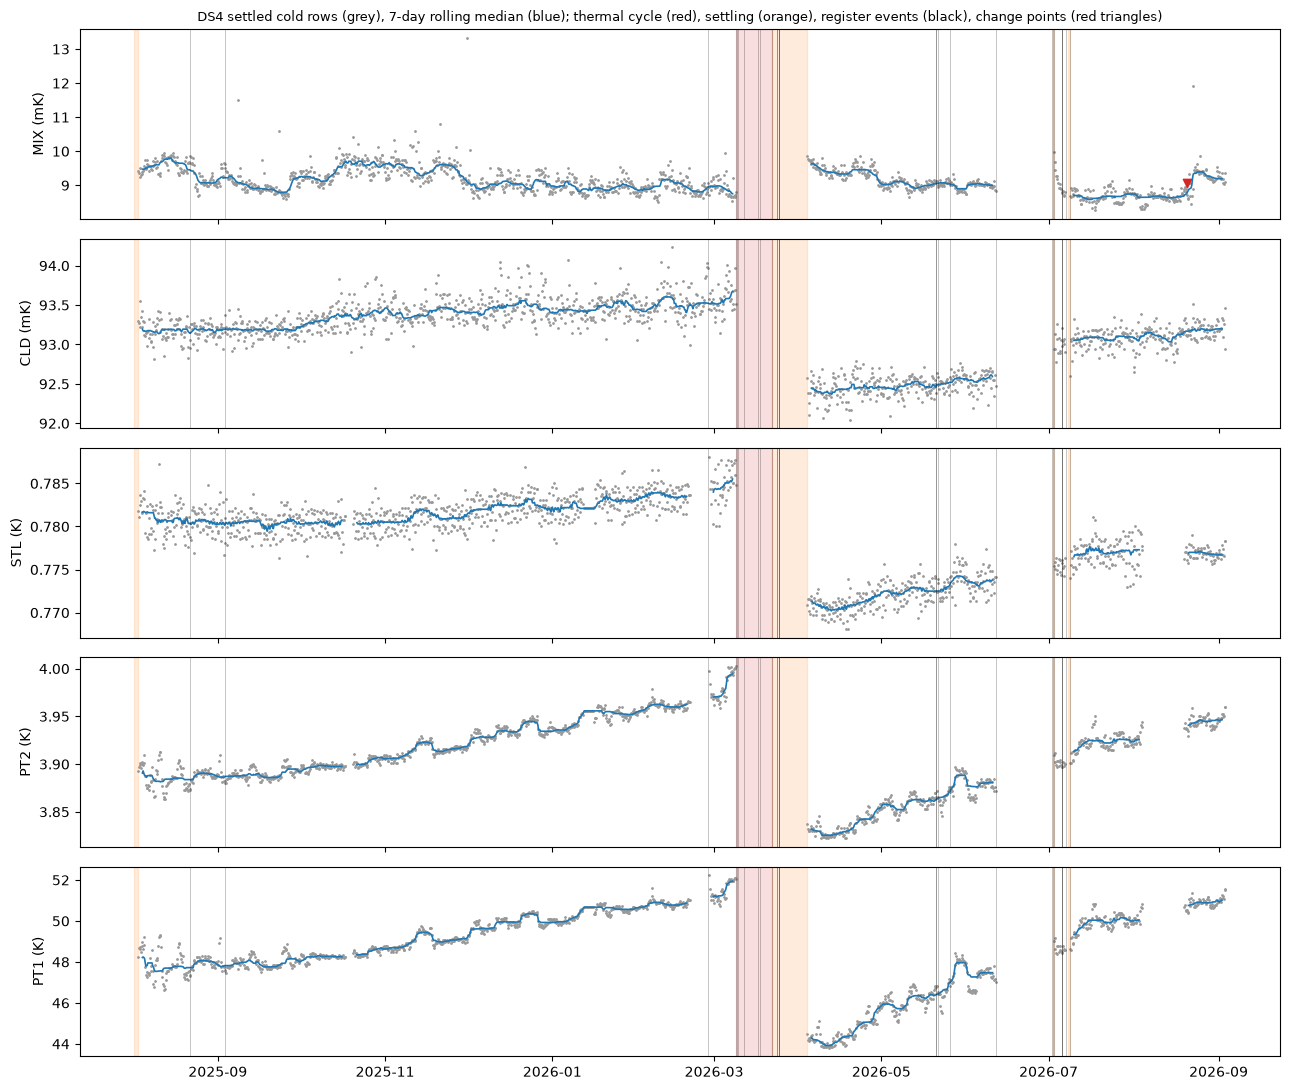

In [20]:
fig, axes = plt.subplots(len(STAGES), 1, figsize=(13, 11), sharex=True)
for ax, (name, c) in zip(axes, STAGES.items()):
    scale, unit = (1e3, "mK") if name in ("MIX", "CLD") else (1, "K")
    ax.plot(x.index, x[c] * scale, ".", ms=2, color="0.6")
    for k, g in xe.groupby("epoch"):
        ax.plot(rolling(grid(g[c]))[0] * scale, color="C0", lw=1.2)
    for _, cy in cyc.iterrows():
        ax.axvspan(cy["last_cold_before"], cy["first_cold_after"], color="C3", alpha=0.15)
    for _, e in ep.iterrows():
        ax.axvspan(e["first"], e["settled_from"], color="C1", alpha=0.15)
    for a in ev5["at"]:
        ax.axvline(pd.Timestamp(a, tz="UTC"), color="k", lw=0.4, alpha=0.4)
    ax.scatter(cp.loc[cp["channel"] == name, "at"], np.full((cp["channel"] == name).sum(), np.nanmedian(x[c]) * scale),
               marker="v", color="C3", zorder=3)
    ax.set_ylabel(f"{name} ({unit})")
axes[0].set_title("DS4 settled cold rows (grey), 7-day rolling median (blue); thermal cycle (red), settling (orange), "
                  "register events (black), change points (red triangles)", fontsize=9)
fig.tight_layout()
out = REPO_ROOT / "docs" / "figures" / "eda" / "b1_ds4_stages.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**
- In the figure, the register events inside the warm-up (red band) are the f01 flag start, the outage start and a DS4 gap. The blank June–July 2026 stretch is the 21-day DS4 gap that starts epoch 2.

## Conclusion

| Result | Status |
|---|---|
| One thermal cycle (2026-03-09 to 03-22) and four cold epochs; epoch 1 takes 13 days to settle | In `periods.py` (`THERMAL_CYCLES`, `SETTLING`, `ds4` break) |
| Incidents 2026-03-09 08:45:16 to 03-24 14:45:52 and 2026-07-02 08:45:41 to 07-05 21:54:09 | Excluded for every source (`INCIDENTS`) |
| The first good run after the cycle is −0.94 MHz off in f01; after July, −0.00 MHz | Break at the cycle end only |
| Six stage channels read exactly 0 in 96 cold rows the mask keeps | Set to NaN in the build |
| Eight representatives from the 0.5 correlation cut | Used downstream |
| MIX level spread (slow sd 0.06–0.26 mK) beats the quantum in every epoch, and the 6 h step in epochs 0–1 | Resolvable over days to weeks |
| Detrended slow sd of PT1, PT2 and flow is 0.13–0.19 of the raw one in epochs 0–1 | Detrend before correlating |
| MIX variance ratio to 6 h is 1.41 at 1 day and 2.53 at 2 days | Test MIX only at lags of 2 days or more |
| The structure function isn't AR(1), and the epochs hold only 7.79 / 2.46 / 2.03 spans of 28 days | Too few spans to test MIX as a covariate within one epoch |
| Change points and MIX spikes match the register no better than chance | No register link |
| MIX spikes on 2025-12-01 and 12-02, just before the early-only channels stop | Open lead |